In [1]:
from math import ceil
from glob import glob
import numpy as np
import matplotlib.pyplot as plt
from flups.io import load_txt, save_txt
from flups.analysis import despike_median, despike_median_slow, despike_median_p, despike_median_partition
from pyspan.utils import nm2ev, between
from ipywidgets import interact, interactive, fixed, interact_manual, GridspecLayout, AppLayout, Button
import ipywidgets as widgets
from numpy.polynomial import Polynomial
from scipy.interpolate import InterpolatedUnivariateSpline
from scipy.spatial.distance import cdist, correlation
#import colorcet as cc
from scipy.signal import savgol_filter
from scipy.ndimage import gaussian_filter
#import scistyles
from tqdm import tqdm

from scipy.ndimage import spline_filter, gaussian_filter

In [2]:
%matplotlib widget

# Select files

In [93]:
#dye = '\C6H'

load_path = r'C:\Users\Felix\Desktop\Machines_FLUPS\data\corrections\C153'#+dye

#  select files
nums = 1, 2, 3
#nums = 25
fnames = [f"\\run{i:02d}.txt" for i in nums] # old: [f"240619_run{i:02d}.txt" for i in nums]
# setup an output root file name
out_root = fnames[0][:-6]+f"{nums[0]:02d}{nums[-1]:02d}"
fnames, out_root

(['\\run01.txt', '\\run02.txt', '\\run03.txt'], '\\run0103')

In [94]:
# Load all ta_data into a dictionnary. It maps {fn: (t, wl, dod)}
dat = {fn: load_txt(load_path+fn) for fn in fnames}
# this should not be necessary in the future
for fn, (t, wl, s) in dat.items():
    if t[1]<t[0]:
        t = t[::-1]
        s = s[::-1,:]
    s = s.T
    dat[fn] = (t, wl, s)

In [95]:
# Check all times are the same
all_t = np.array([d[0] for d in dat.values()])
assert np.allclose(all_t[0], all_t)
t = all_t[0]
# Check all wavelengths are the same
all_wl = np.array([d[1] for d in dat.values()])
assert np.allclose(all_wl[0], all_wl)
wl = all_wl[0]
pix = np.arange(wl.size)
if np.allclose(wl, np.arange(wl.size)+1): # convert pixels to energy
    wl_u = 0.171025+249,59

# Load all the delta A data.
sig = np.array([d[2] for d in dat.values()])
org = sig.copy()
# subtract before time 0
#bksub = dod - np.mean(dod.compress(t<-0.15, axis=2), axis=2)[:,:,np.newaxis]

In [96]:
all_t

array([[100., 100., 100., 100., 100., 100., 100., 100., 100., 100.],
       [100., 100., 100., 100., 100., 100., 100., 100., 100., 100.],
       [100., 100., 100., 100., 100., 100., 100., 100., 100., 100.]])

In [97]:
# The axes of dod are: files, wl, time
sig.shape, (len(fnames), wl.size, t.size)

((3, 1600, 10), (3, 1600, 10))

In [98]:
def spectra_view(wl, t, dat1, ylim=[-30,40], compare=False, dat2=0, name1='dat1', name2='dat2'):
    'interactive view for clicking though spectra'
    fig, ax = plt.subplots(dpi=100, figsize=(10, 5))
    line_1, = ax.plot(wl, dat1[:, 0], color='k', label=name1, linewidth=0.8)
    if compare==True:
        line_2, = ax.plot(wl, dat2[:, 0], color='b', label=name2, linewidth=0.8)
    plt.axhline(0, color='k', lw=0.6)
    ax.set_xlim(265, 687)
    ax.set_ylim(ylim[0], ylim[1])
    ax.set_xlabel('wavelength / nm')
    ax.set_ylabel(f"$\Delta OD$/ $10^3$")
    ax.set_title(f'Delay = {t[0]:.1f} ps')
    ax.grid()
    ax.legend()
    plt.tight_layout()

    def update(time_index):
        line_1.set_ydata(dat1[:, time_index])
        if compare==True:
            line_2.set_ydata(dat2[:, time_index])
        ax.set_title(f'delay = {t[time_index]:.2f} ps')
        fig.canvas.draw_idle()

    return interact(update, time_index=(0, len(t) - 1, 1));

interactive(children=(IntSlider(value=4, description='time_index', max=9), Output()), _dom_classes=('widget-in…

<function __main__.spectra_view.<locals>.update(time_index)>

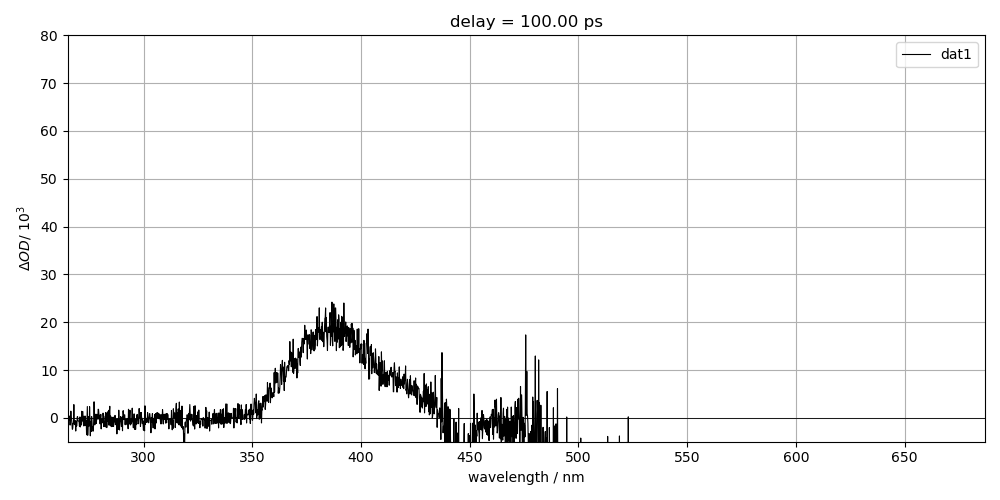

In [99]:
spectra_view(wl, t, sig[0,:,:], ylim=[-5,80], compare=False, dat2=0, name1='dat1', name2='dat2')

# plot the traces

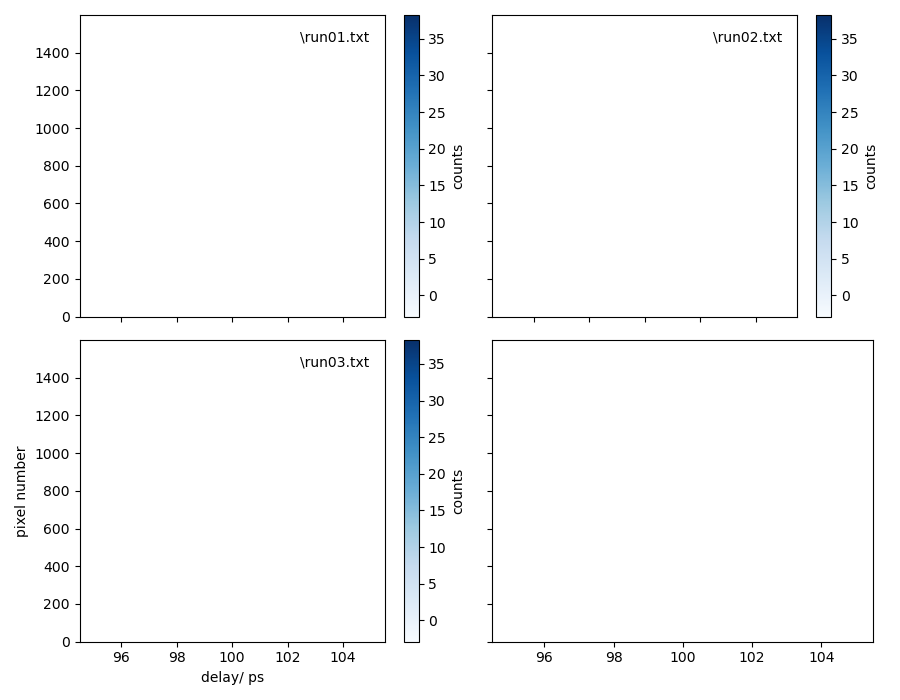

In [100]:
colorscheme = "Blues" # new

vmin, vmax = np.percentile(sig, [10, 99])

nrows = ceil(len(fnames)/2)
fig, axes = plt.subplots(nrows=nrows, ncols=2, sharex=True, sharey=True, figsize=(9,nrows*3.5))
for i, (fn, ax) in enumerate(zip(fnames, axes.flat)):
    plt.sca(ax)
    mesh = plt.pcolormesh(t, pix, sig[i,:,:], cmap=colorscheme, vmin=vmin, vmax=vmax) # old: cmap="cet_CET_L17"
    plt.colorbar(mesh, ax=ax, label=f"counts") # new
    plt.text(0.95, 0.95, fnames[i], transform=ax.transAxes, va="top", ha="right")
plt.xlabel('delay/ ps')
plt.ylabel('pixel number')
plt.tight_layout()
plt.show()

# filter spikes

3it [00:00, 12.33it/s]


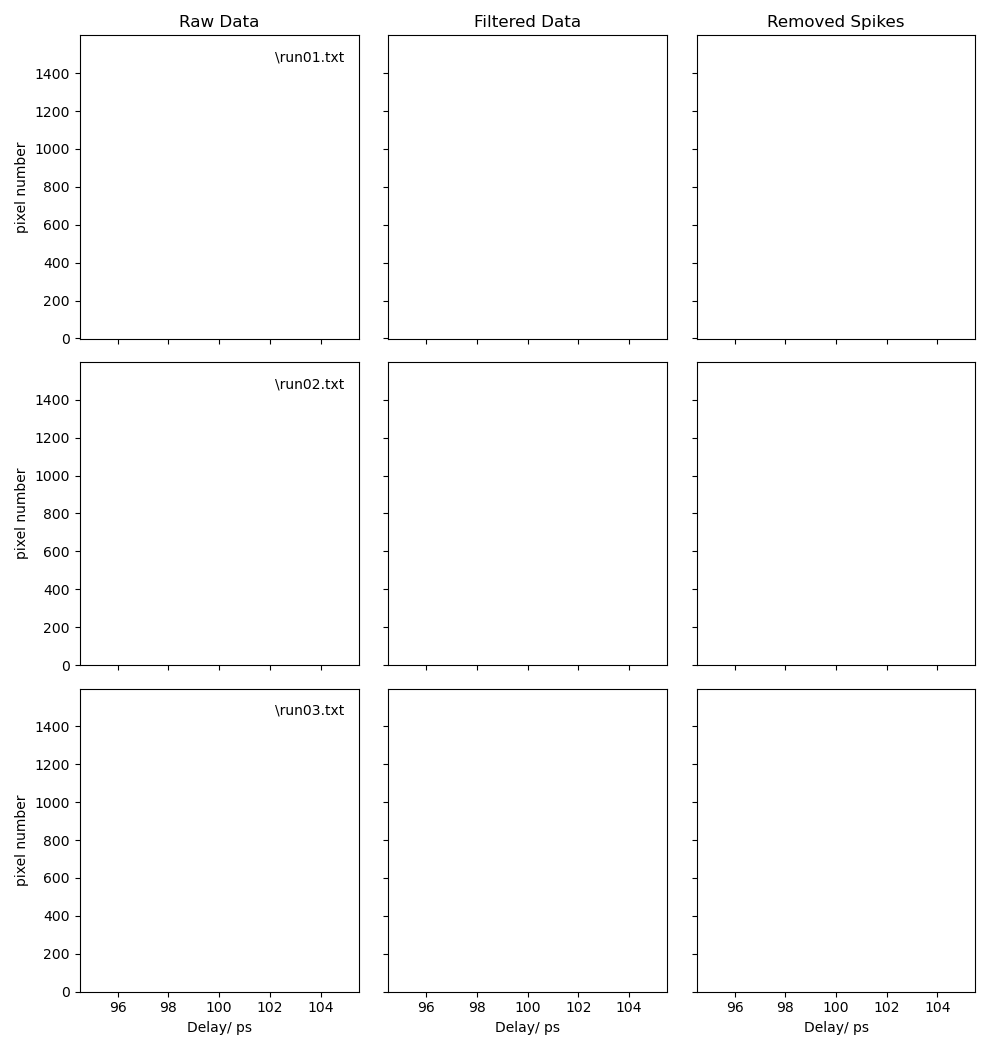

In [101]:
# calculate threshold for spike detection
lo, hi = 0,100
thres = (hi-lo)*2
filter_len = (15,5)

# Filter out spikes and plot results
nrows = len(fnames)
fig, axes = plt.subplots(nrows=nrows, ncols=3, sharex=True, sharey=True, figsize=(10,nrows*3.5))
axes = np.atleast_2d(axes)
filt = []
for i, fn in tqdm(enumerate(fnames)):
    filt.append(despike_median(sig[i,:,:], filter_len, threshold=thres))
    plt.sca(axes[i,0])
    plt.pcolormesh(t, pix, sig[i,:,:], cmap=colorscheme, vmin=vmin, vmax=vmax)
    plt.text(0.95, 0.95, fnames[i], transform=plt.gca().transAxes, va="top", ha="right")
    plt.sca(axes[i,1])
    plt.pcolormesh(t, pix, filt[i], cmap=colorscheme, vmin=vmin, vmax=vmax)
    plt.sca(axes[i,2])
    plt.pcolormesh(t, pix, sig[i,:,:]-filt[i], cmap="seismic_r", vmin=-vmax/100, vmax=vmax/100)
for ax in axes[:,0]:
    ax.set_ylabel(r"pixel number")
for ax in axes[-1,:]:
    ax.set_xlabel(r"Delay/ ps")
axes[0,0].set_title("Raw Data")
axes[0,1].set_title("Filtered Data") 
axes[0,2].set_title("Removed Spikes")
plt.tight_layout()
plt.show()

In [102]:
sig = np.array(filt)

# average

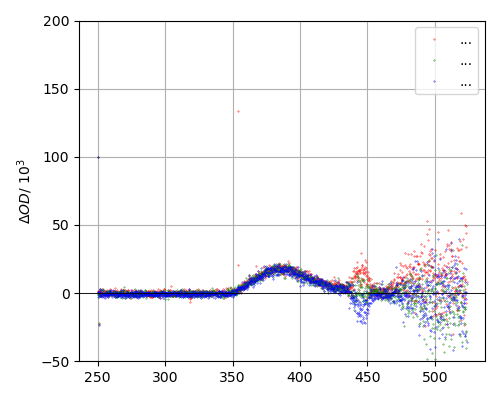

In [103]:
#changed wl_u to wl

plt.figure(figsize=(5,4))
plt.plot(wl, sig[0,:,9], '.', markersize=0.6, lw=0.5, color='r', label=f'...')
plt.plot(wl, sig[1,:,9], '.', markersize=0.6, lw=0.5, color='g', label=f'...')
plt.plot(wl, sig[2,:,9], '.', markersize=0.6, lw=0.5, color='b', label=f'...')
plt.axhline(0, color='k', lw=0.6)
plt.xlim()
plt.ylim(-50,200)
plt.grid()
plt.legend()
plt.xlabel('')
plt.ylabel(f"$\Delta OD$/ $10^3$")
plt.title('')
plt.tight_layout()
plt.show()

In [104]:
# average of scans
avg1 = np.ma.mean(sig, axis=0)
# average over timepoints
avg2 = np.ma.mean(avg1, axis=1)

print(avg1.shape)

#np.savetxt("260605_FLUPS_pcf_PBBO.txt", np.column_stack((wl, avg2)))

(1600, 10)


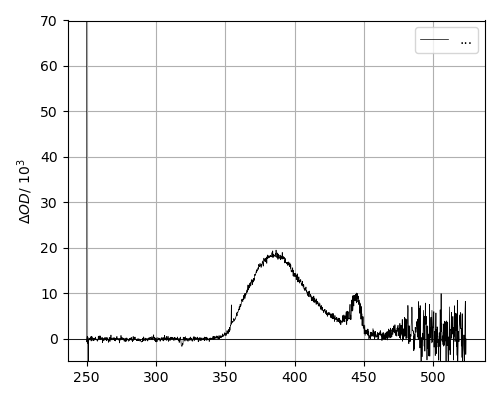

In [105]:
plt.figure(figsize=(5,4))
plt.plot(wl, avg2, '-', markersize=0.6, lw=0.5, color='k', label=f'...')
plt.axhline(0, color='k', lw=0.6)
plt.xlim()
plt.ylim(-5, 70)
plt.grid()
plt.legend()
plt.xlabel('')
plt.ylabel(f"$\Delta OD$/ $10^3$")
plt.title('')
plt.tight_layout()
#plt.savefig("PBBO_PCF_260605")
plt.show()

In [106]:
wl_f = 1/(1/wl - 1/1340) # do downconversion

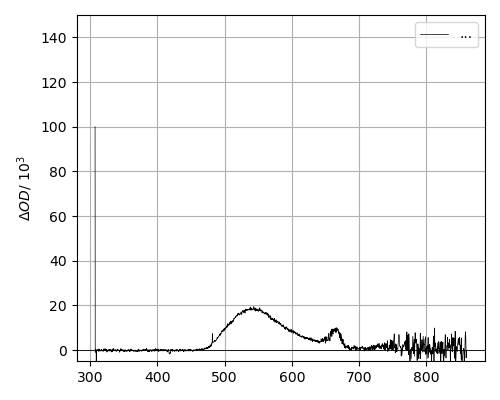

In [107]:
plt.figure(figsize=(5,4))
plt.plot(wl_f, avg2, '-', markersize=0.6, lw=0.5, color='k', label=f'...')
plt.axhline(0, color='k', lw=0.6)
plt.xlim()
plt.ylim(-5, 150)
plt.grid()
plt.legend()
plt.xlabel('')
plt.ylabel(f"$\Delta OD$/ $10^3$")
plt.title('')
plt.tight_layout()
plt.show()